# Matplotlib：分布の表示と保存の検証

対応する本文は [Matplotlib による可視化](../chapters/matplotlib.tex) である。コードセルを上から順にShift+Enterで実行する。各問の説明にある値や図と、セルの下に表示される結果を比べる。ファイルを作る問では、その直前に保存先を用意する。

## 描くデータを確認する

次は動作確認用の5地点の経度、緯度、マグニチュードと、7個の発生間隔である。経度と緯度を点の位置、マグニチュードを色に使う。人工データなので、実際の観測結果としては解釈しない。

In [1]:
import matplotlib.pyplot as plt
import numpy as np

longitude = np.array([140.0, 141.2, 139.5, 142.0, 138.7])
latitude = np.array([35.0, 36.1, 34.8, 37.0, 33.9])
magnitude = np.array([3.2, 4.1, 2.8, 4.8, 3.7])
dt = np.array([1.0, 4.0, 12.0, 60.0, 180.0, 900.0, 3600.0])

## 問1：5地点を色付きの点で描く

横軸を経度、縦軸を緯度にする。`plt.subplots()` は、図全体の `fig` と点を描く領域の `ax` を返す。`ax.scatter()` は各地点へ点を置く。まず保存先を作り、その後のセルを実行する。

### 保存先を用意する

この後のセルではファイルを作る。次のセルを実行して、`notebooks/_outputs/08_matplotlib/` を用意する。表示された場所に結果が保存され、同名の実習用ファイルは再実行すると置き換わる。

Notebookは教材の `notebooks` フォルダー、または教材の一番上のフォルダーから実行する。`Path.cwd()` は現在のフォルダーを調べ、`mkdir()` は保存先を作る。

In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "main.tex").is_file():
    raise FileNotFoundError("教材のフォルダーか notebooks フォルダーから実行してください。")
WORK = ROOT / "notebooks" / "_outputs" / "08_matplotlib"
WORK.mkdir(parents=True, exist_ok=True)
print("Python", sys.version.split()[0])
print("保存先:", WORK.relative_to(ROOT))

Python 3.12.14
保存先: notebooks/_outputs/08_matplotlib


In [3]:
FIGURES = WORK / "figures"
FIGURES.mkdir(exist_ok=True)

この後のセルにある `assert 条件` は、結果を自動で確認する命令である。条件が違っていればエラーで止まり、条件を満たせば次へ進む。何も表示されなくても、エラーが出なければその確認は通っている。画面の数値や図も、説明に示した値と比べる。

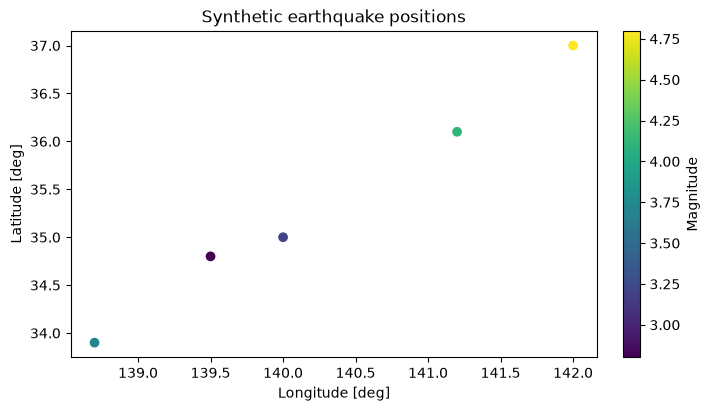

In [4]:
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
scatter = ax.scatter(longitude, latitude, c=magnitude, cmap="viridis")
fig.colorbar(scatter, ax=ax, label="Magnitude")
ax.set(xlabel="Longitude [deg]", ylabel="Latitude [deg]", title="Synthetic earthquake positions")
fig.savefig(FIGURES / "usgs_global_scatter.pdf")
plt.show()
plt.close(fig)
assert (FIGURES / "usgs_global_scatter.pdf").exists()

点が5個あり、右に色とマグニチュードの対応を示すカラーバーがあることを確認する。`scatter` には点群の情報が返り、`fig.colorbar(scatter, ax=ax)` がその色を説明する。カラーバーも描画領域の一つなので、`fig.axes` は合計2個になる。保存したPDFは表示された保存先の `figures` にある。

次のセルで、点の色に渡した数値と描画領域の数を確かめる。図を閉じた後も、変数からこれらの情報を読み取れる。

`np.testing.assert_array_equal()` は二つの配列の全要素が同じかを調べる。ここでは、点の色が元の5個のマグニチュードに対応していることを確認する。

In [5]:
np.testing.assert_array_equal(scatter.get_array(), magnitude)
assert len(fig.axes) == 2

## 問2：対数軸と対数ビンを分ける

対数軸は表示尺度を変え、元の配列値は変えない。0以下の値と空ビンの度数0は対数では表示できない。空ビンを数える処理と、作図上の扱いを区別する。不等幅の棒の高さは度数であり、密度ではない。密度を比べる場合は `density=True` でビン幅も除く。

対数軸では、例えば1、10、100が等間隔に並ぶ。ここでの度数は各ビンに入った件数、密度は「件数 / 表示範囲内の総件数 / ビン幅」である。密度の棒は高さと幅を掛けた面積の合計が1となる。

Linear bins 空ビン: 3
Logarithmic bins 空ビン: 7


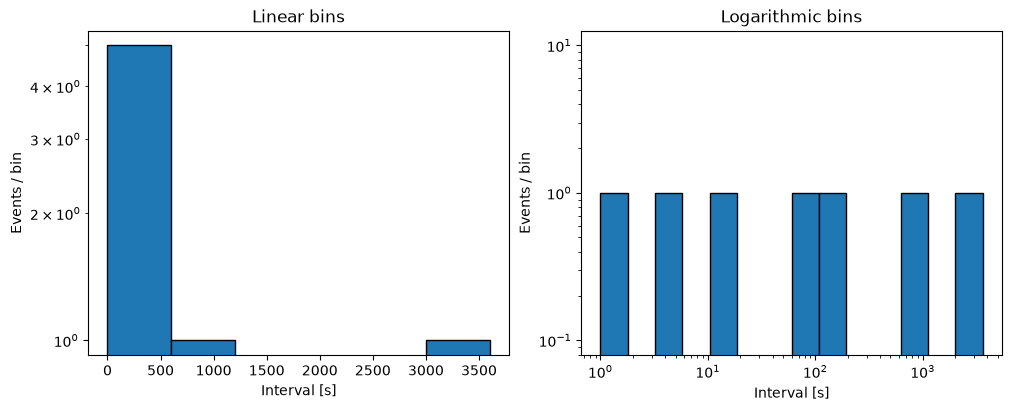

In [6]:
positive = dt[np.isfinite(dt) & (dt > 0)]
assert len(positive) == len(dt)
linear_edges = np.arange(0, 3601, 600)
log_edges = np.logspace(0, np.log10(3600), 15)
log_edges[-1] = 3600
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, bins, title in zip(axes, [linear_edges, log_edges], ["Linear bins", "Logarithmic bins"]):
    counts, _ = np.histogram(positive, bins=bins)
    ax.hist(positive, bins=bins, edgecolor="black")
    ax.set_yscale("log")
    ax.set(xlabel="Interval [s]", ylabel="Events / bin", title=title)
    assert counts.sum() == len(positive)
    print(title, "空ビン:", np.count_nonzero(counts == 0))
axes[1].set_xscale("log")
fig.savefig(FIGURES / "interval_comparison.pdf")
plt.show()
plt.close(fig)
assert (FIGURES / "interval_comparison.pdf").exists()

## 問3：Cartopy で座標系を指定する

`projection` は描画先の座標系、`transform` は入力の座標系を指定する。同じ PlateCarree でも役割は異なる。経度と緯度をそのまま描く場合も、入力を明示する。

発展セルは `RUN_CARTOPY = True` に変更すると実行する。事前に端末で `python -m pip install cartopy` を実行する。海岸線の初回描画には Natural Earth データのダウンロードが必要になる場合がある。未導入時の例外は `ModuleNotFoundError` である。

In [7]:
RUN_CARTOPY = False
if RUN_CARTOPY:
    import cartopy.crs as ccrs
    fig, ax = plt.subplots(figsize=(8, 4), subplot_kw={"projection": ccrs.PlateCarree()}, layout="constrained")
    ax.set_global()
    ax.coastlines()
    points = ax.scatter(longitude, latitude, c=magnitude, transform=ccrs.PlateCarree())
    fig.colorbar(points, ax=ax, label="Magnitude", shrink=0.7)
    ax.set_title("Synthetic earthquake positions")
    fig.savefig(FIGURES / "usgs_map.pdf")
    plt.show()
    plt.close(fig)
else:
    print("海岸線の描画は Cartopy と地図データを用意してから実行します。")

海岸線の描画は Cartopy と地図データを用意してから実行します。
